# Figure 2 — benchmark: retrieval, held-out contexts, knockdown strength, compute and scaling

Renders panels A–I from the cached benchmark tables in `data/` (written by `fig2_data.py`). A–C read the pseudobulk tables in `data/pbulk/`; D–I the per-cell / cost tables in `data/`. Panels go to `render/`. (The sbatch plot step also writes `fig2b_radar_spokes.pdf`; not reproduced here.)

In [1]:
import sys
from pathlib import Path
_paper = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'scripts' / 'common').is_dir())
sys.path.insert(0, str(_paper / 'scripts' / 'common'))
import nbtools as nb                      # puts paper/scripts/*/ on sys.path

vs = nb.vizstyle()
DATA, INPUTS, OUT, SRC = nb.folders()     # data/ (cache), inputs/, render/, render/src/

In [2]:
import json
import fig2_common as F
import fig2_plot as P

P.setup(DATA, str(nb.STYLE))                       # palette from data/fig2_palette.csv
meta = json.loads((DATA / 'fig2_meta.json').read_text())
metrics = [meta.get('f1', F.F1), F.R10, meta['mrr']]   # F1, top-10 recall, MRR
PB = DATA / 'pbulk'                                 # pseudobulk tables (panels A-C)

## A — radar, ID (top) and OOD (bottom), pseudobulk, one shared linear ladder

  wrote fig2a_radar.svg / .png


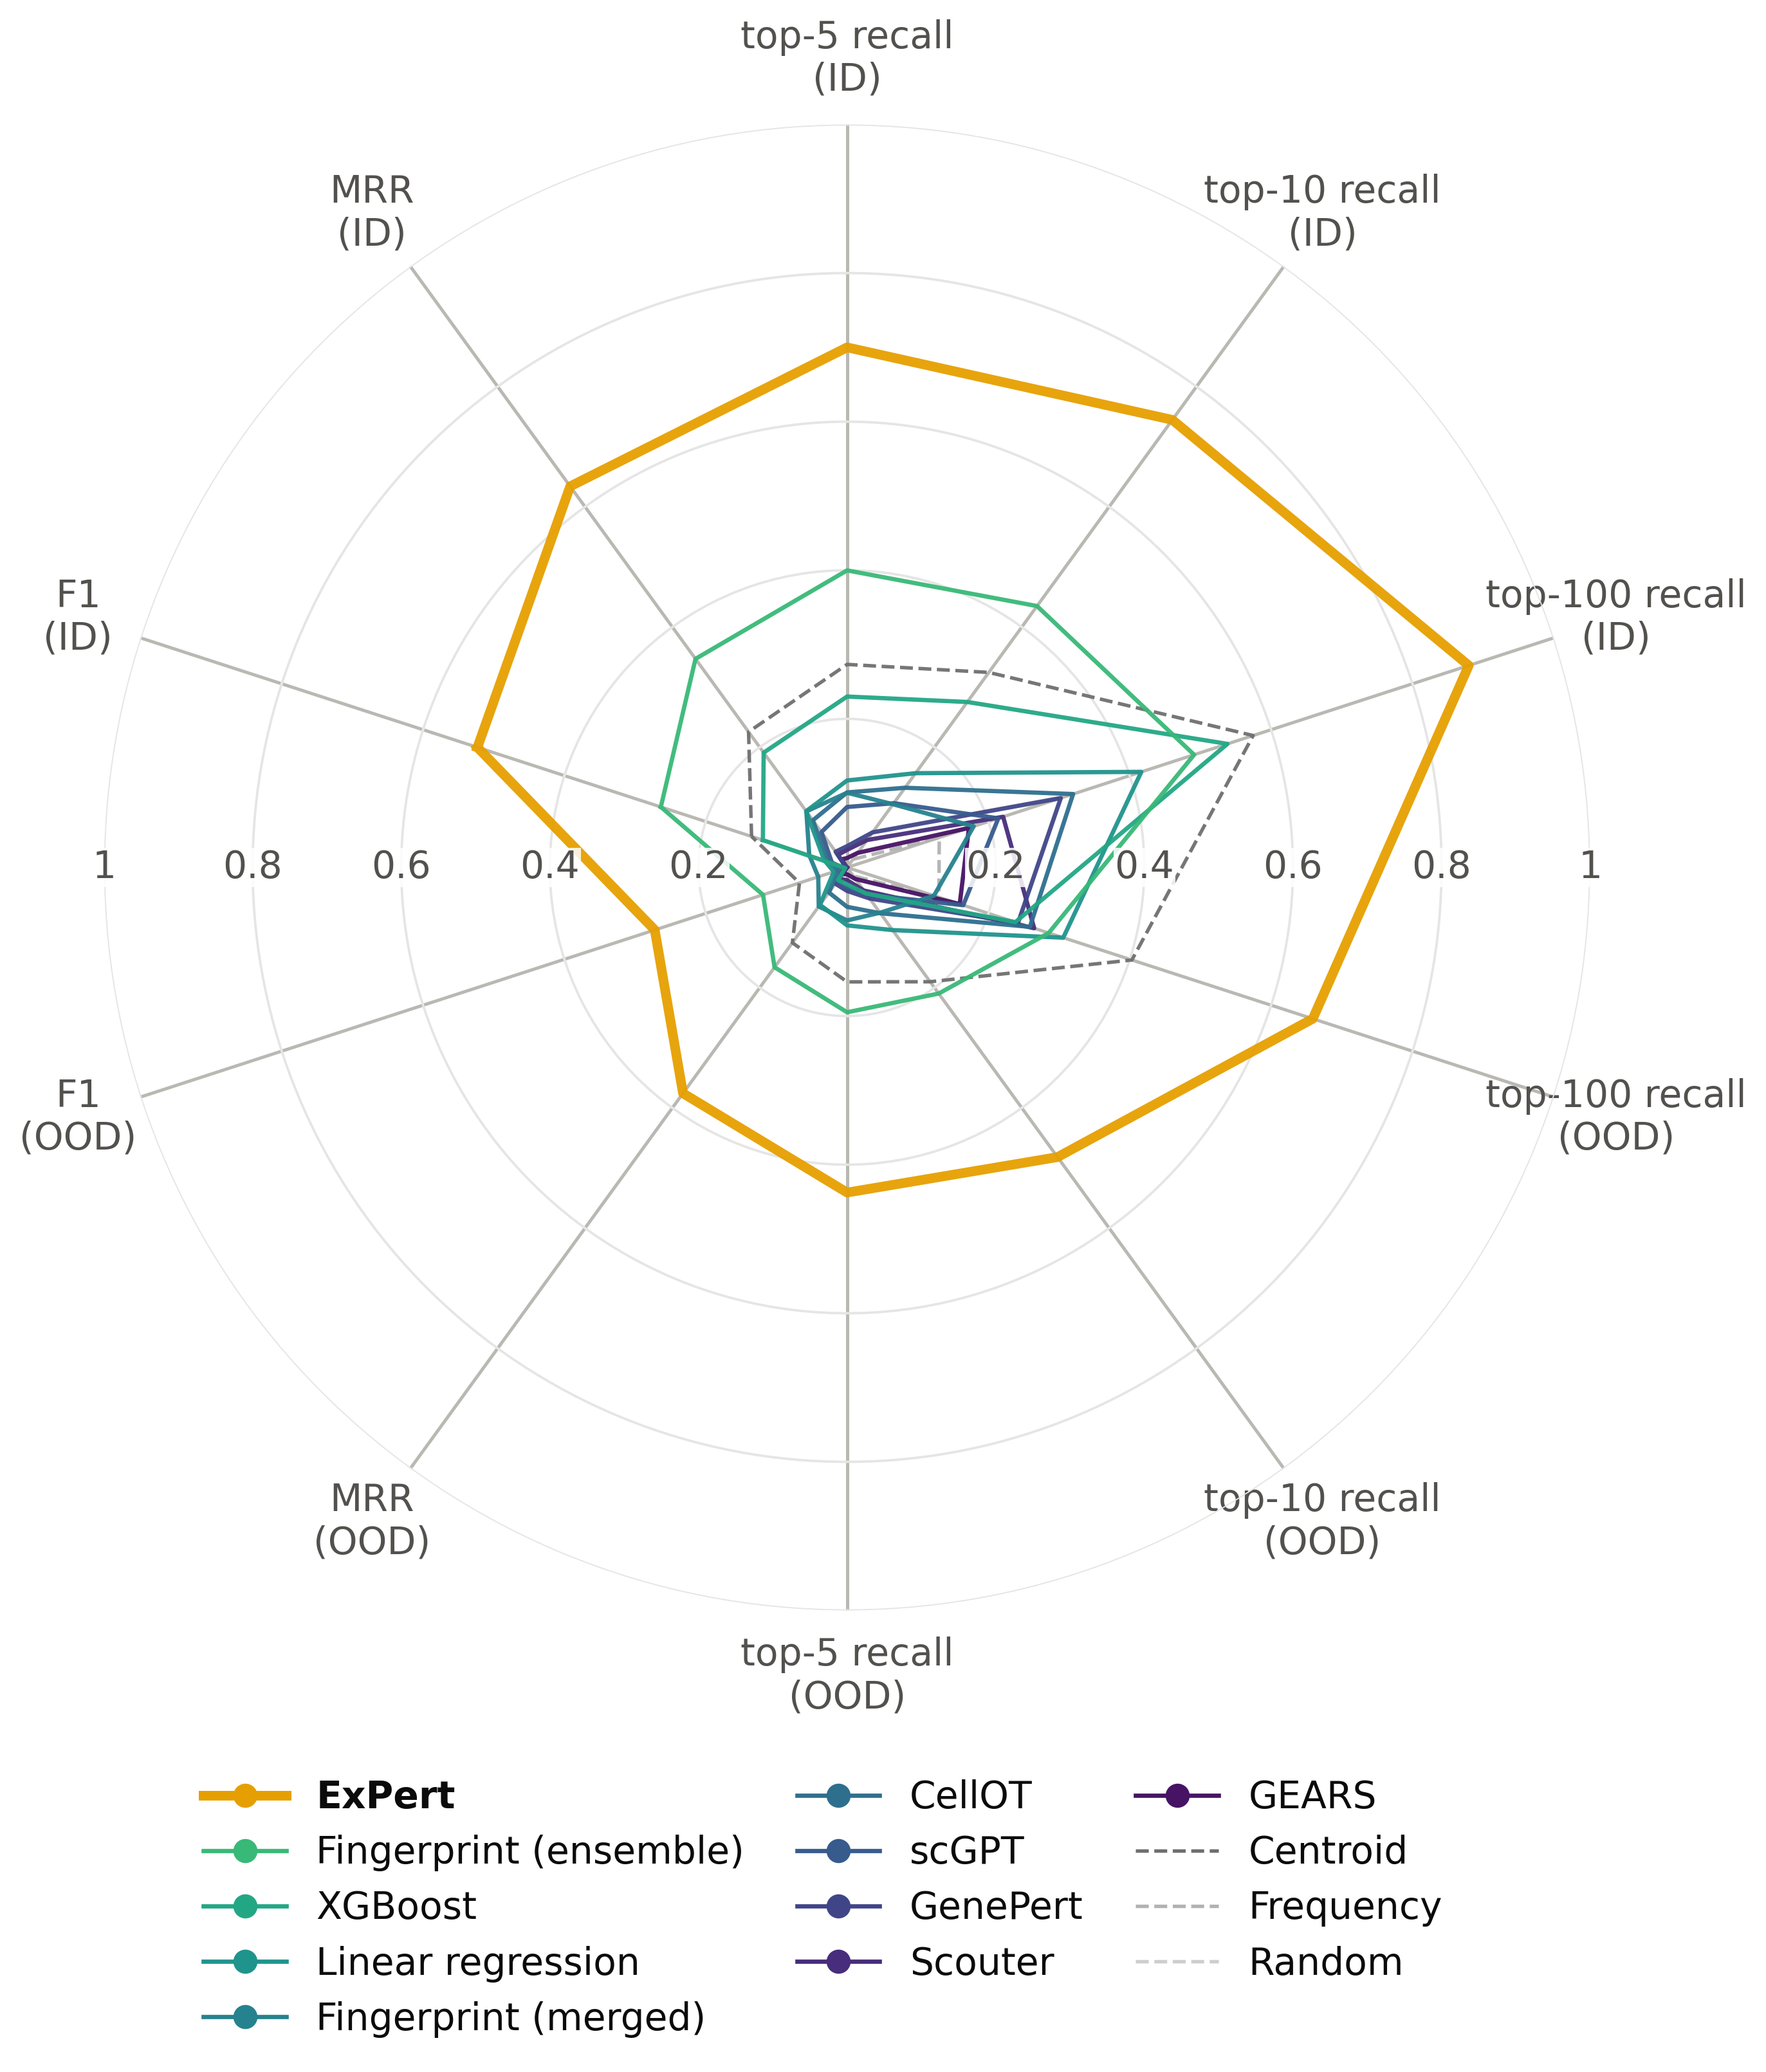

In [3]:
P.radar_shared(PB, OUT, 'fig2a_radar')
nb.show(OUT, 'fig2a_radar')

## B — the same radar, each spoke on its own scale (fold change over random)

  wrote fig2b_radar_spokes.svg / .png


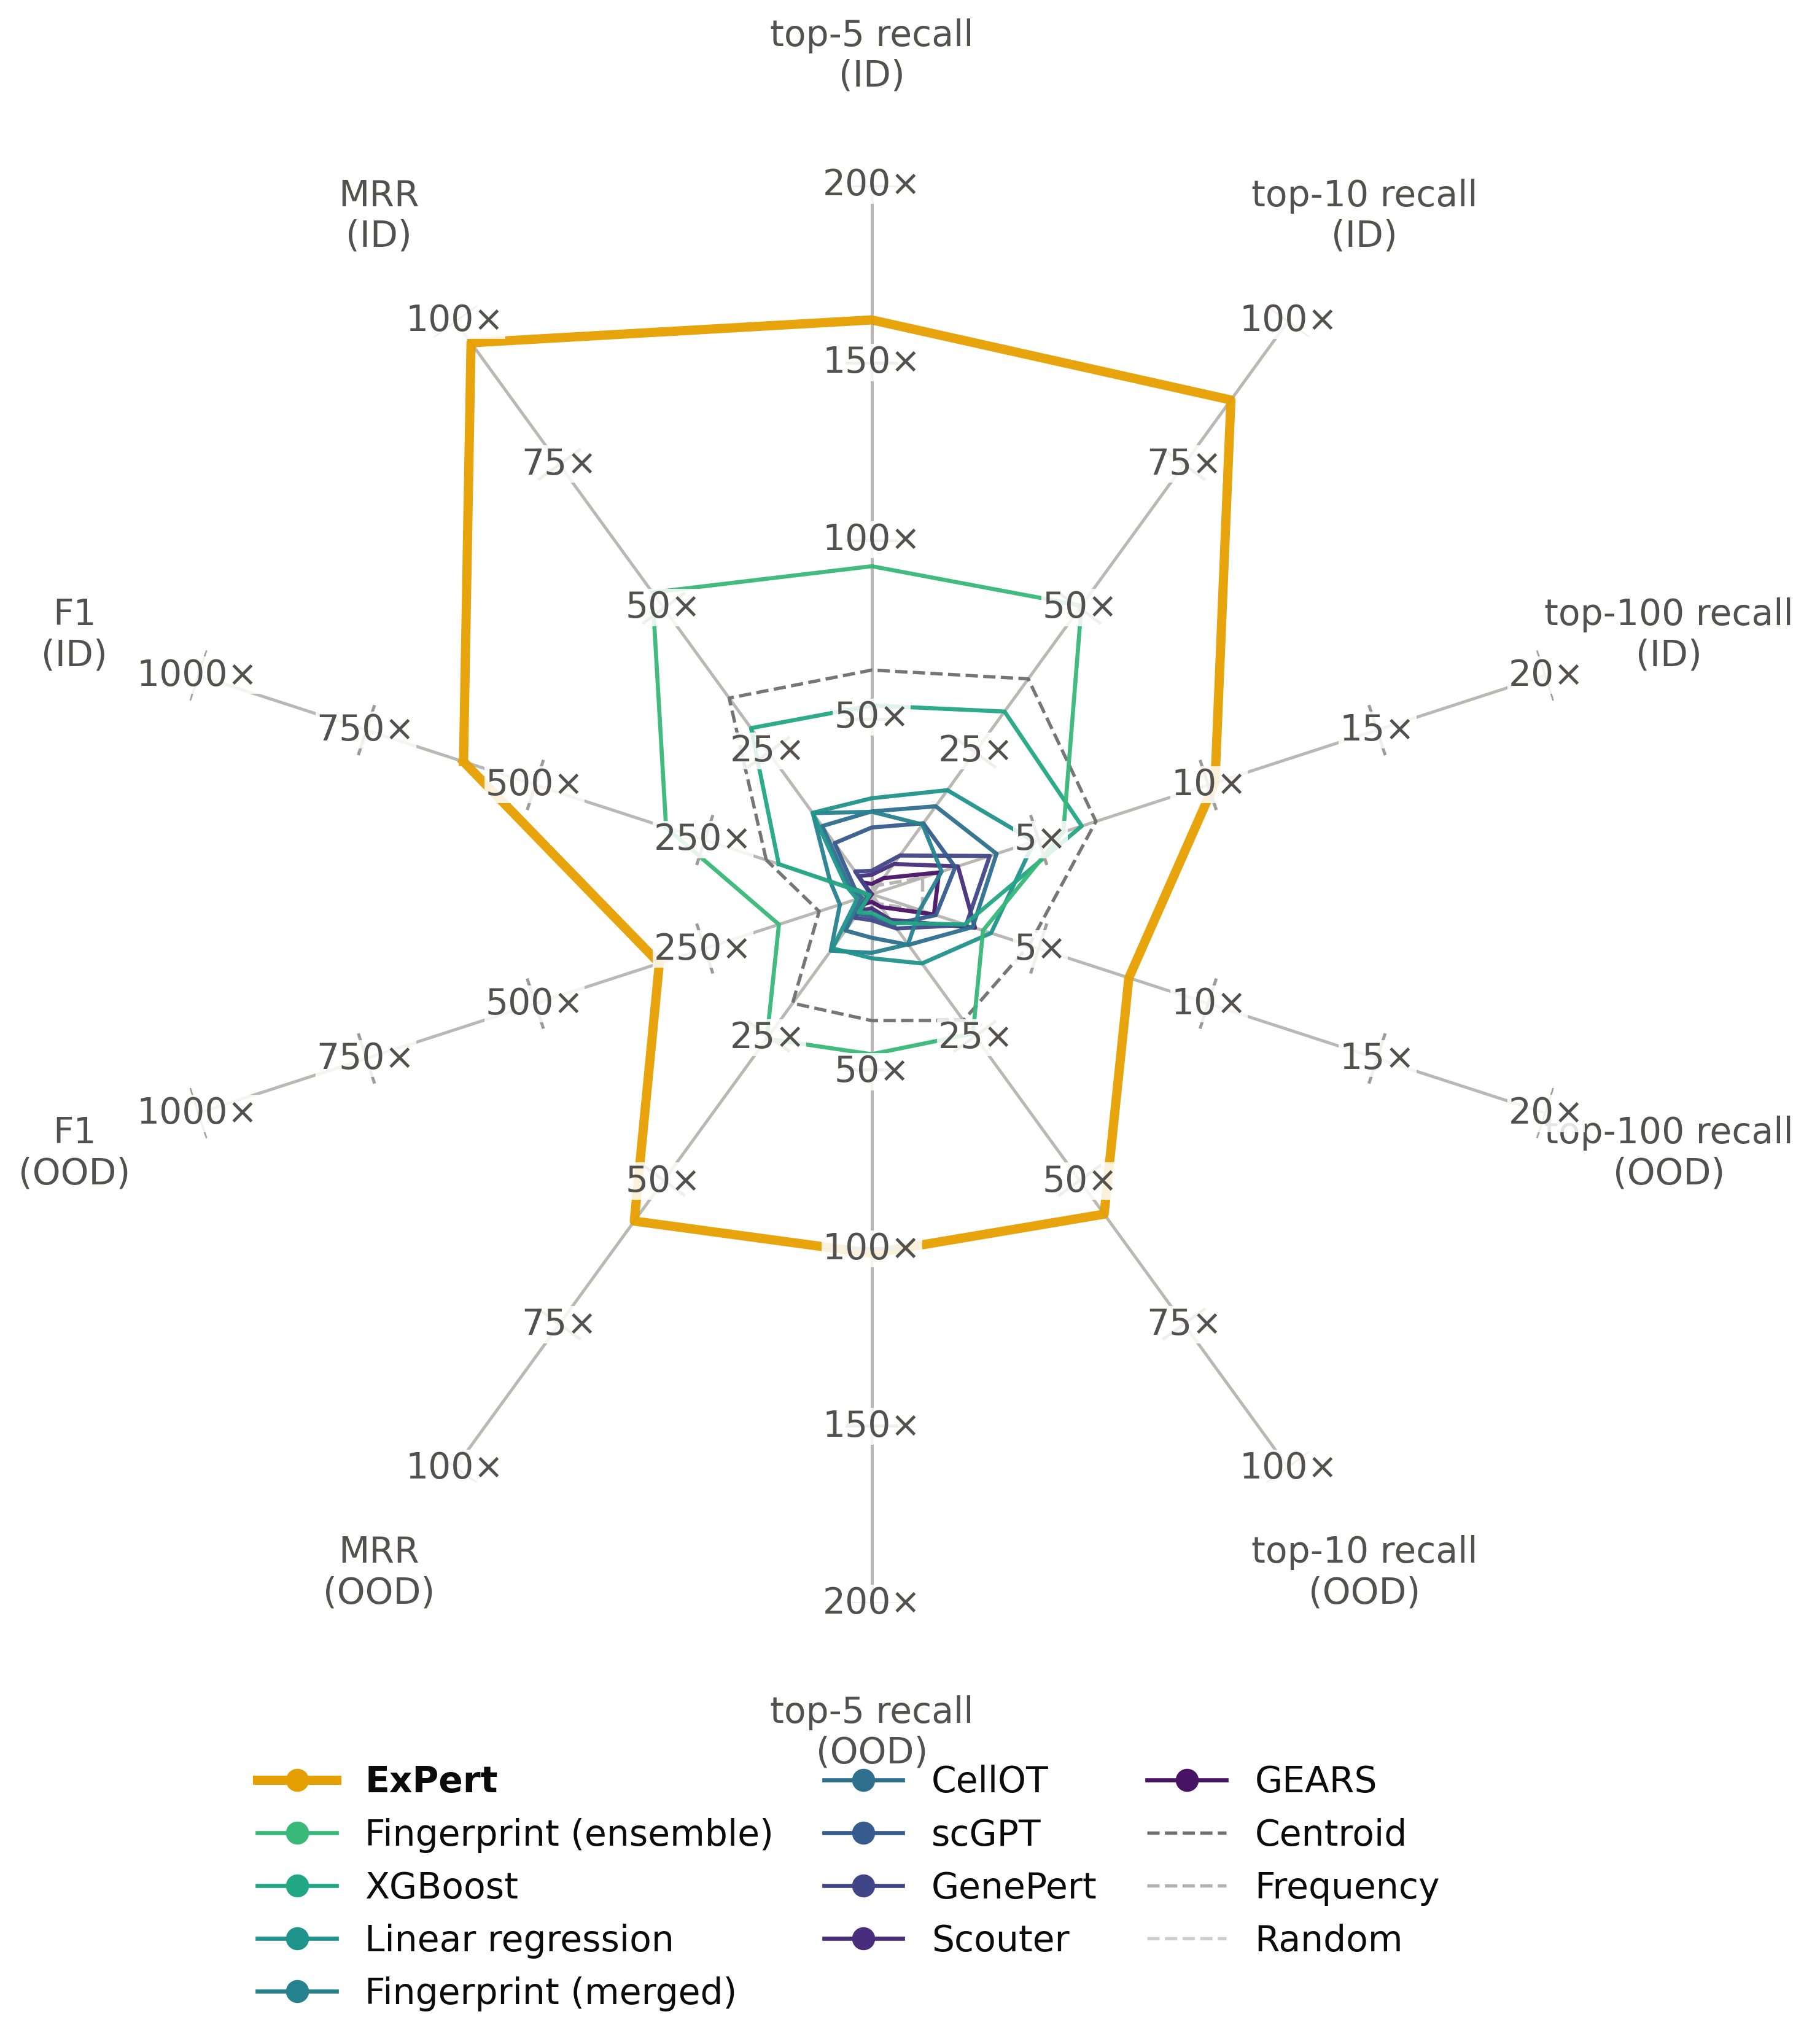

In [4]:
P.radar_spokes(PB, OUT, 'fig2b_radar_spokes')
nb.show(OUT, 'fig2b_radar_spokes')

## C — OOD by held-out context (cell line / donor), pseudobulk

  wrote fig2c_ood_by_shift.svg / .png


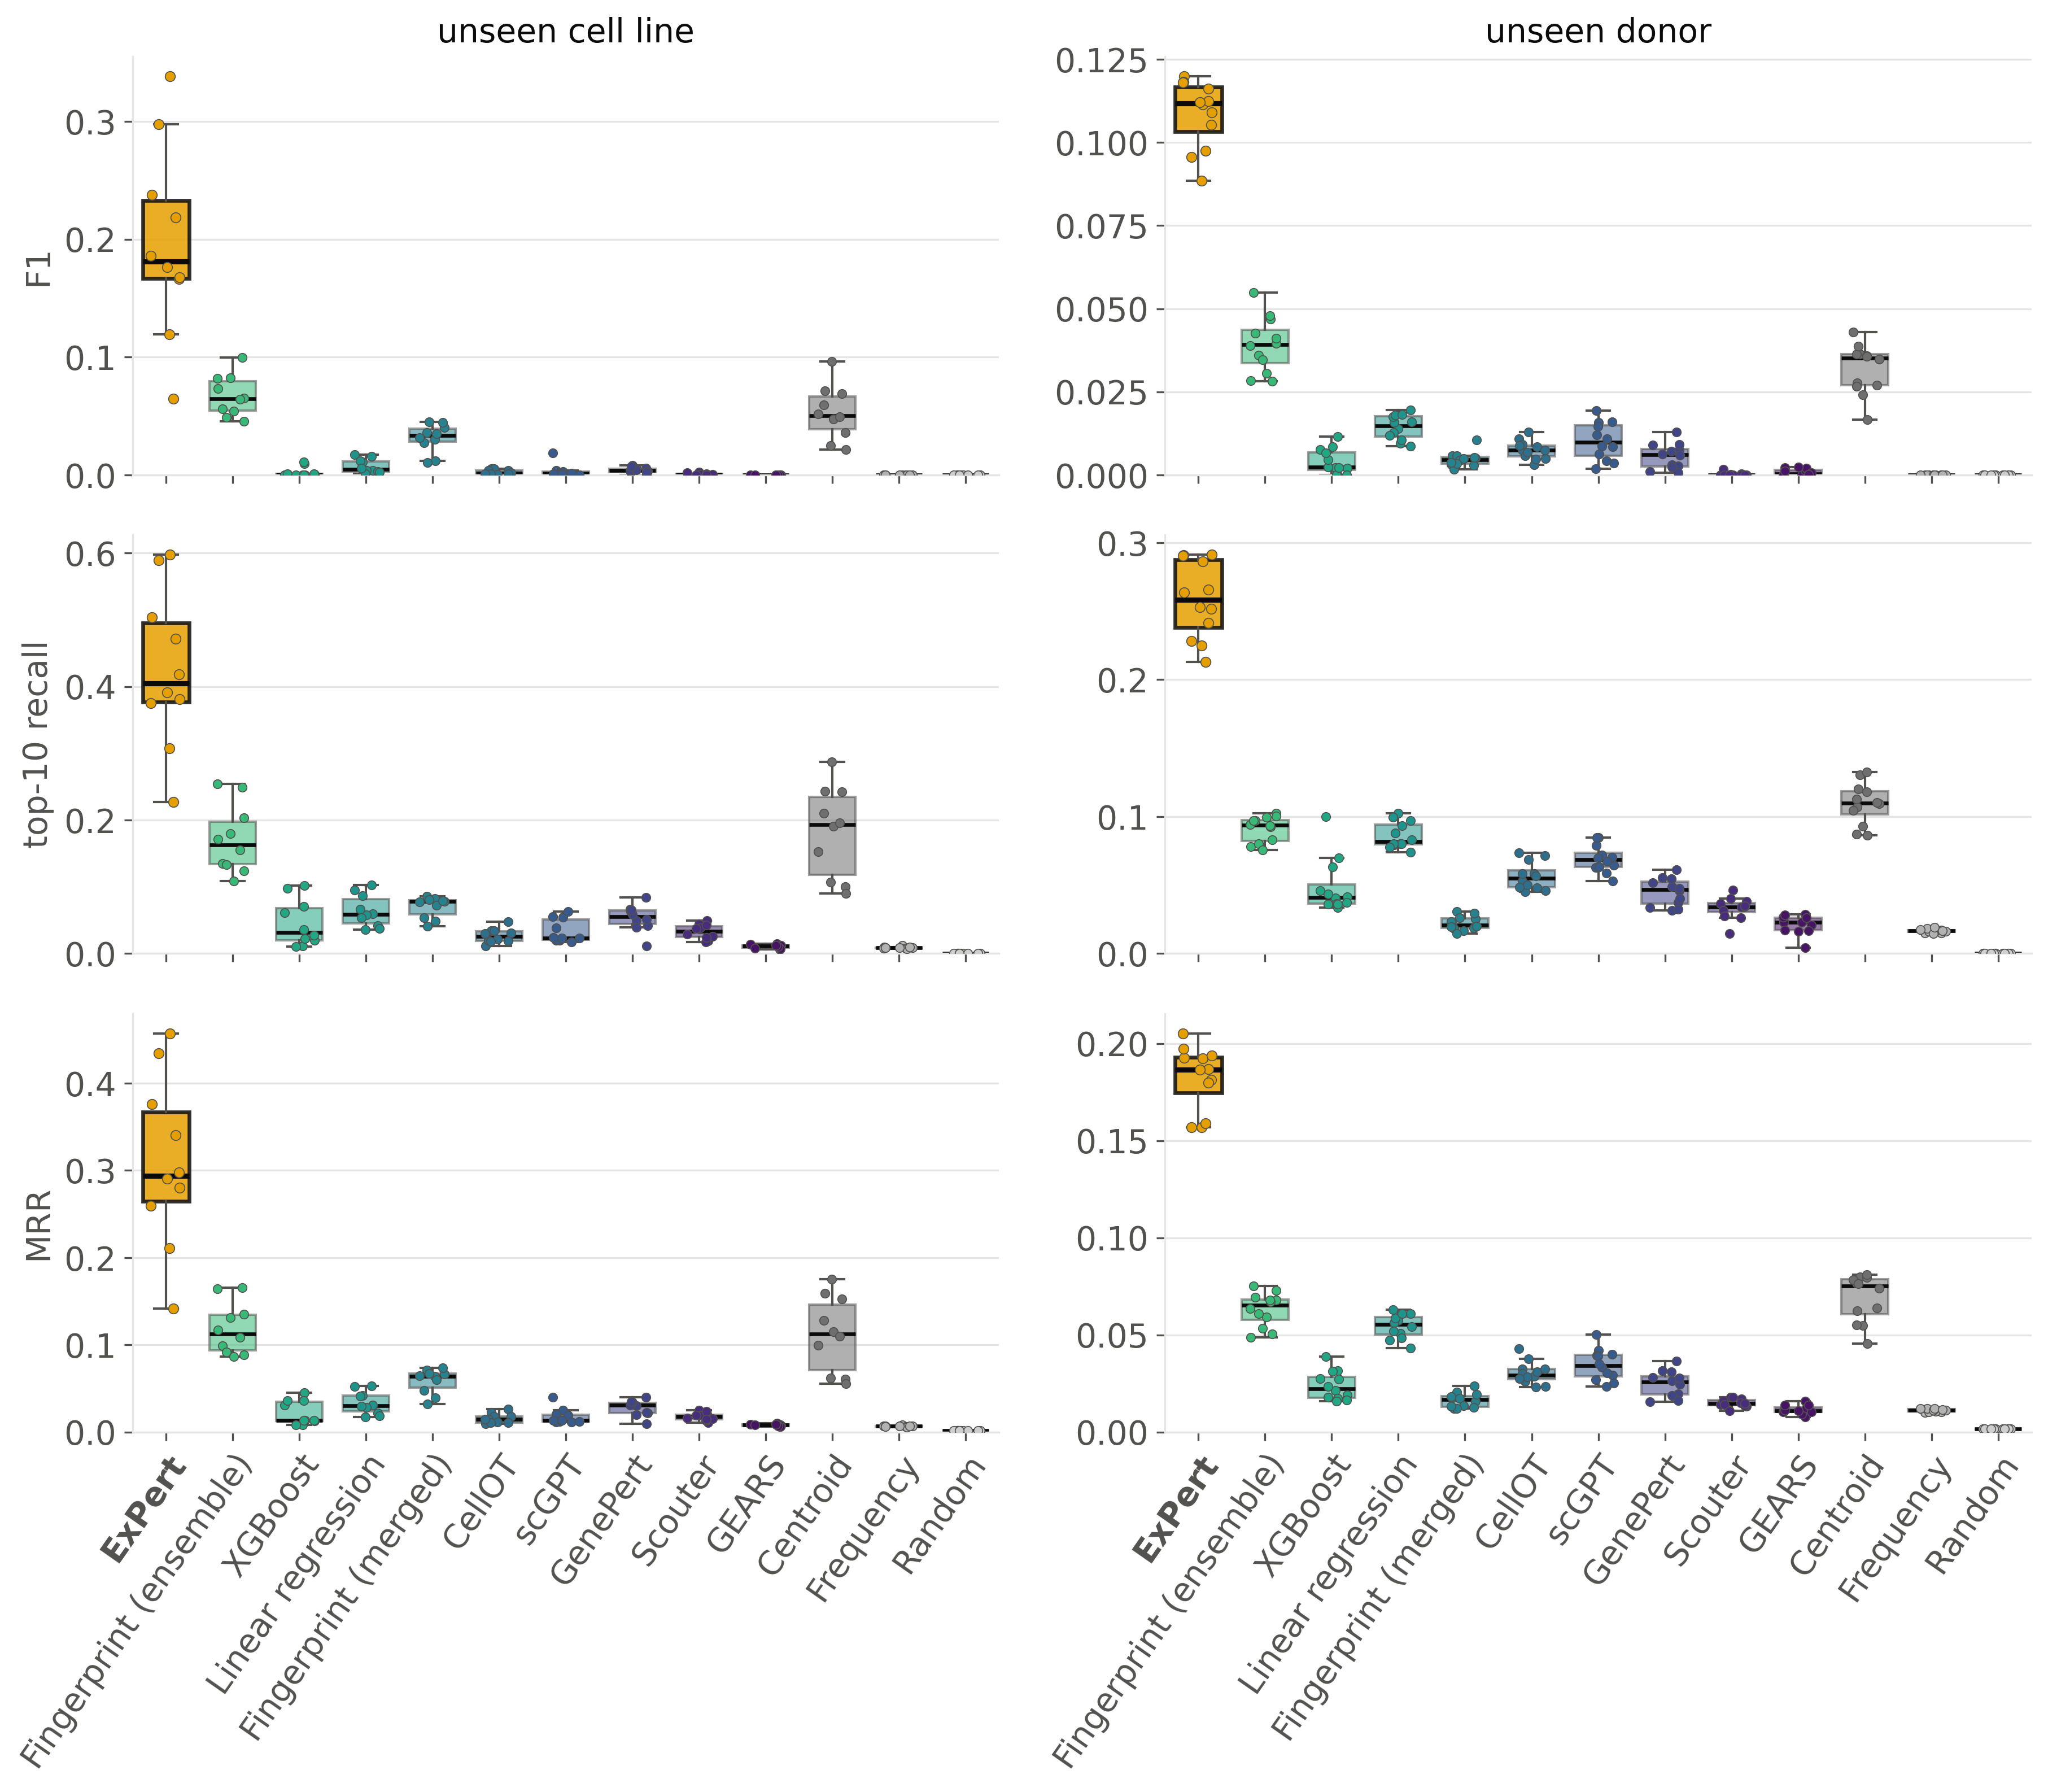

In [5]:
P.panel_b(PB, OUT, metrics)
nb.show(OUT, 'fig2c_ood_by_shift')

## D — OOD single cells by minimum knockdown effect size, with effect-size/score Spearman ρ

  wrote fig2d_efficiency.svg / .png


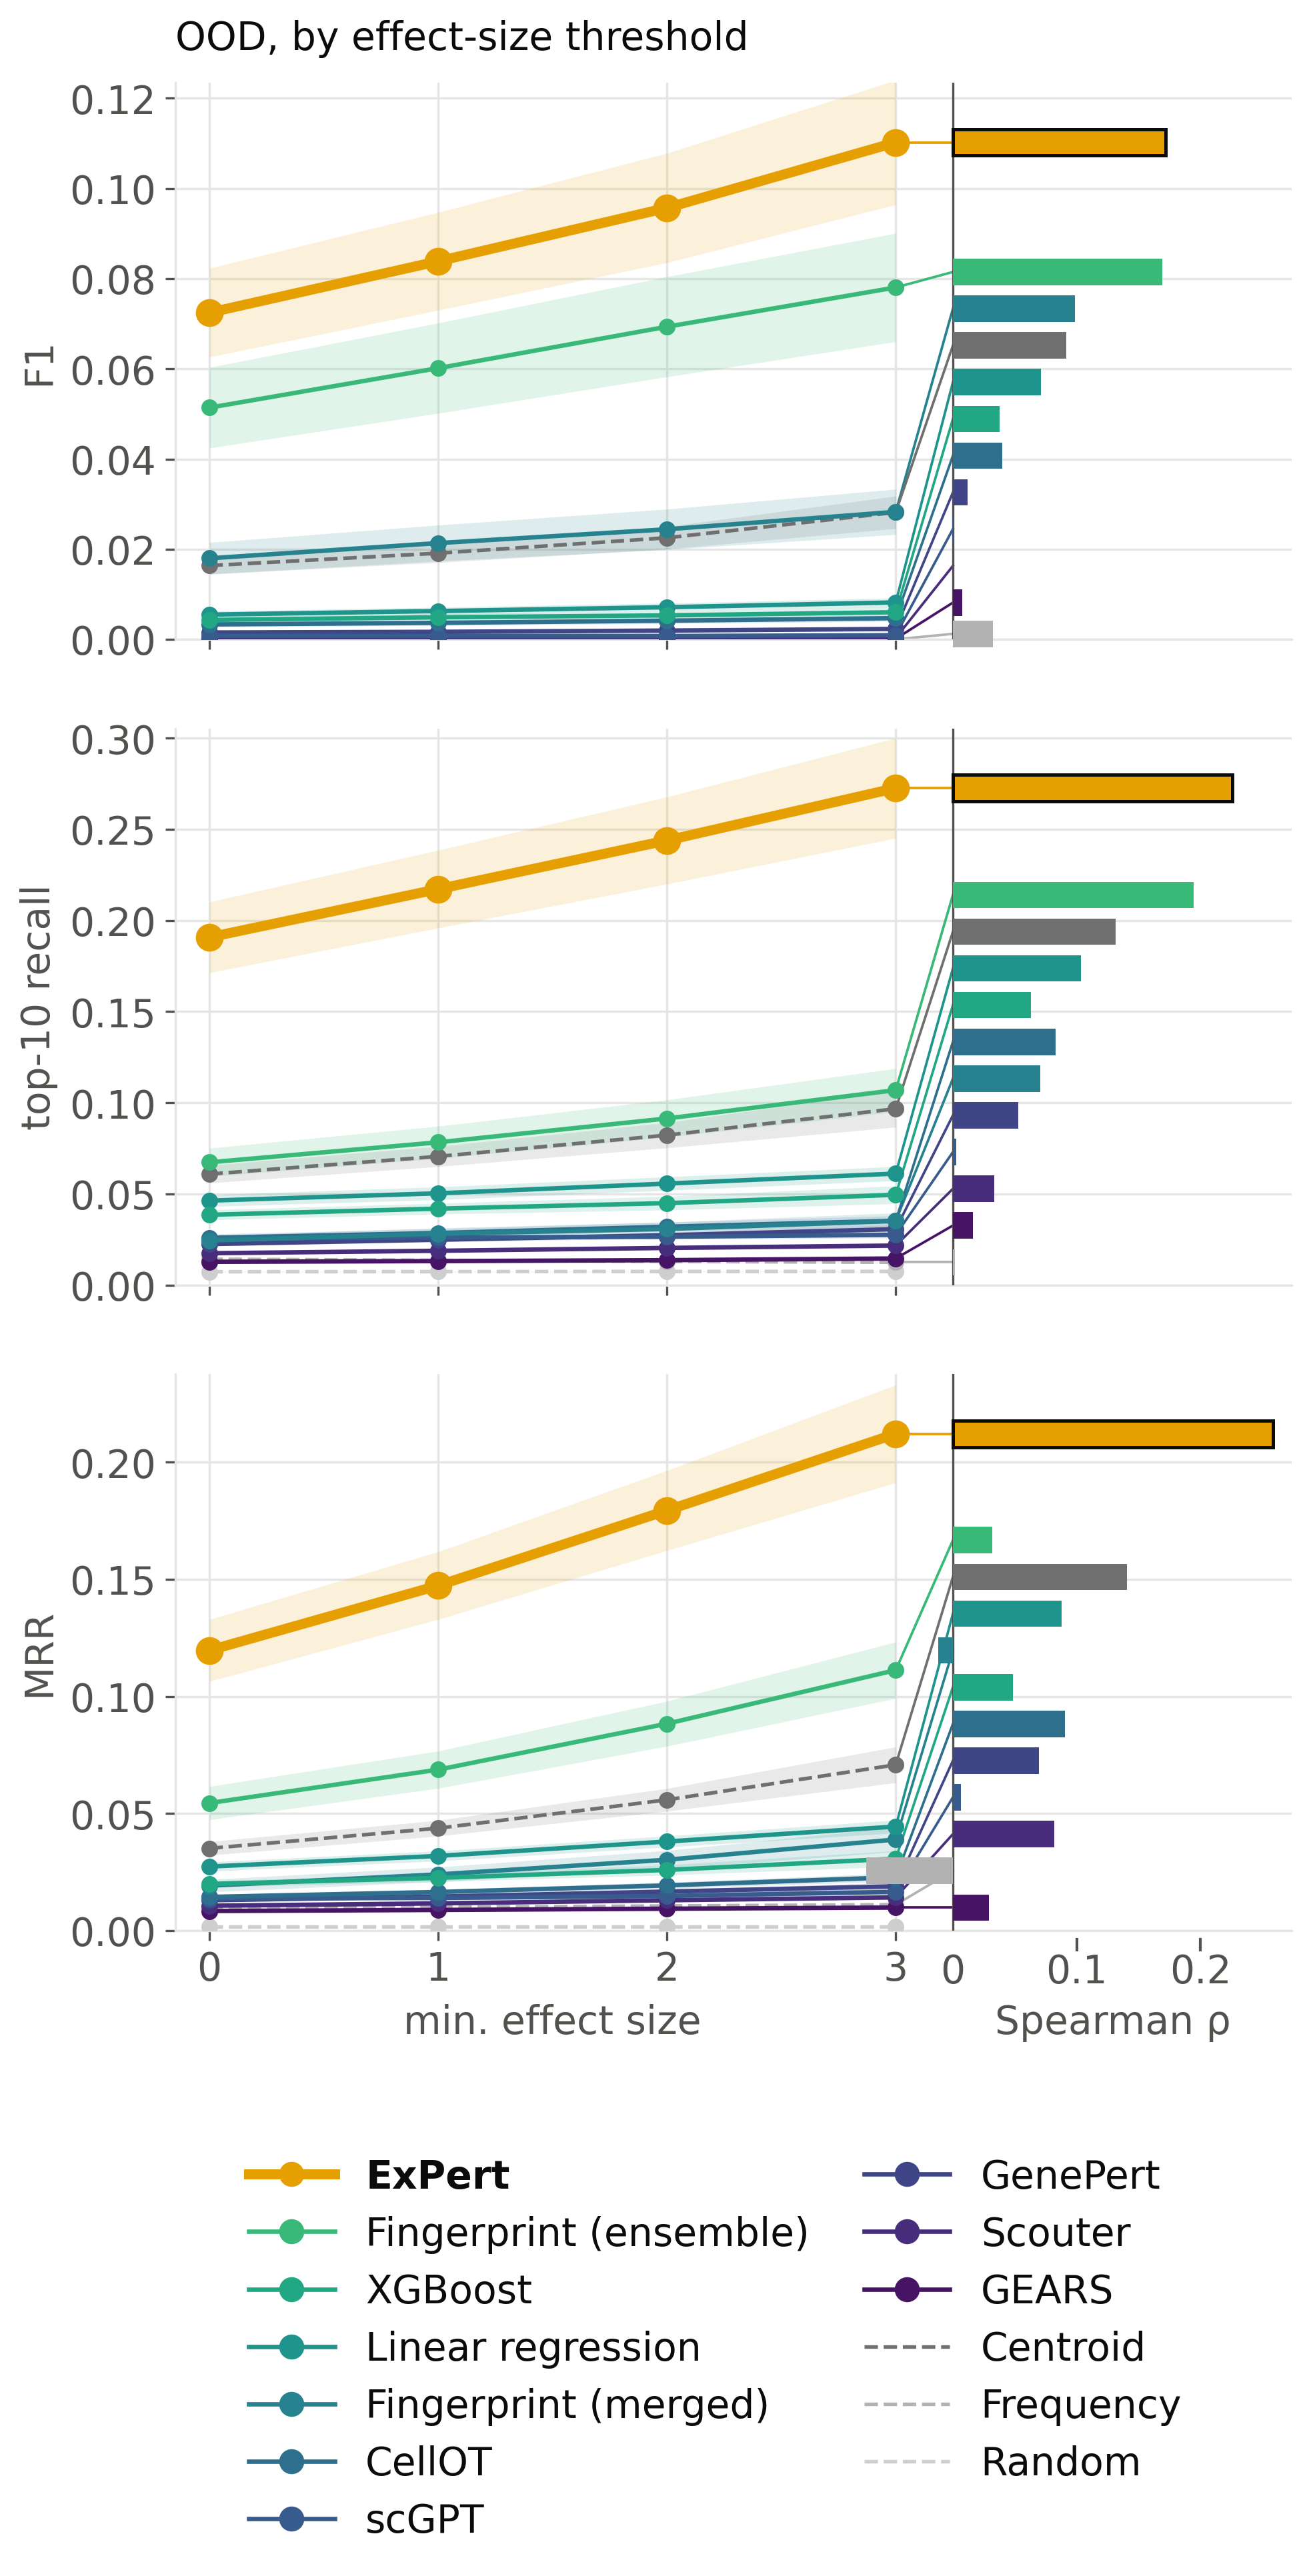

In [6]:
P.panel_c(DATA, OUT)   # panel D is drawn by panel_c
nb.show(OUT, 'fig2d_efficiency')

## E — total evaluation compute per method (CPU core-h / GPU-h, broken axis)

  wrote fig2f_eval_compute.svg / .png


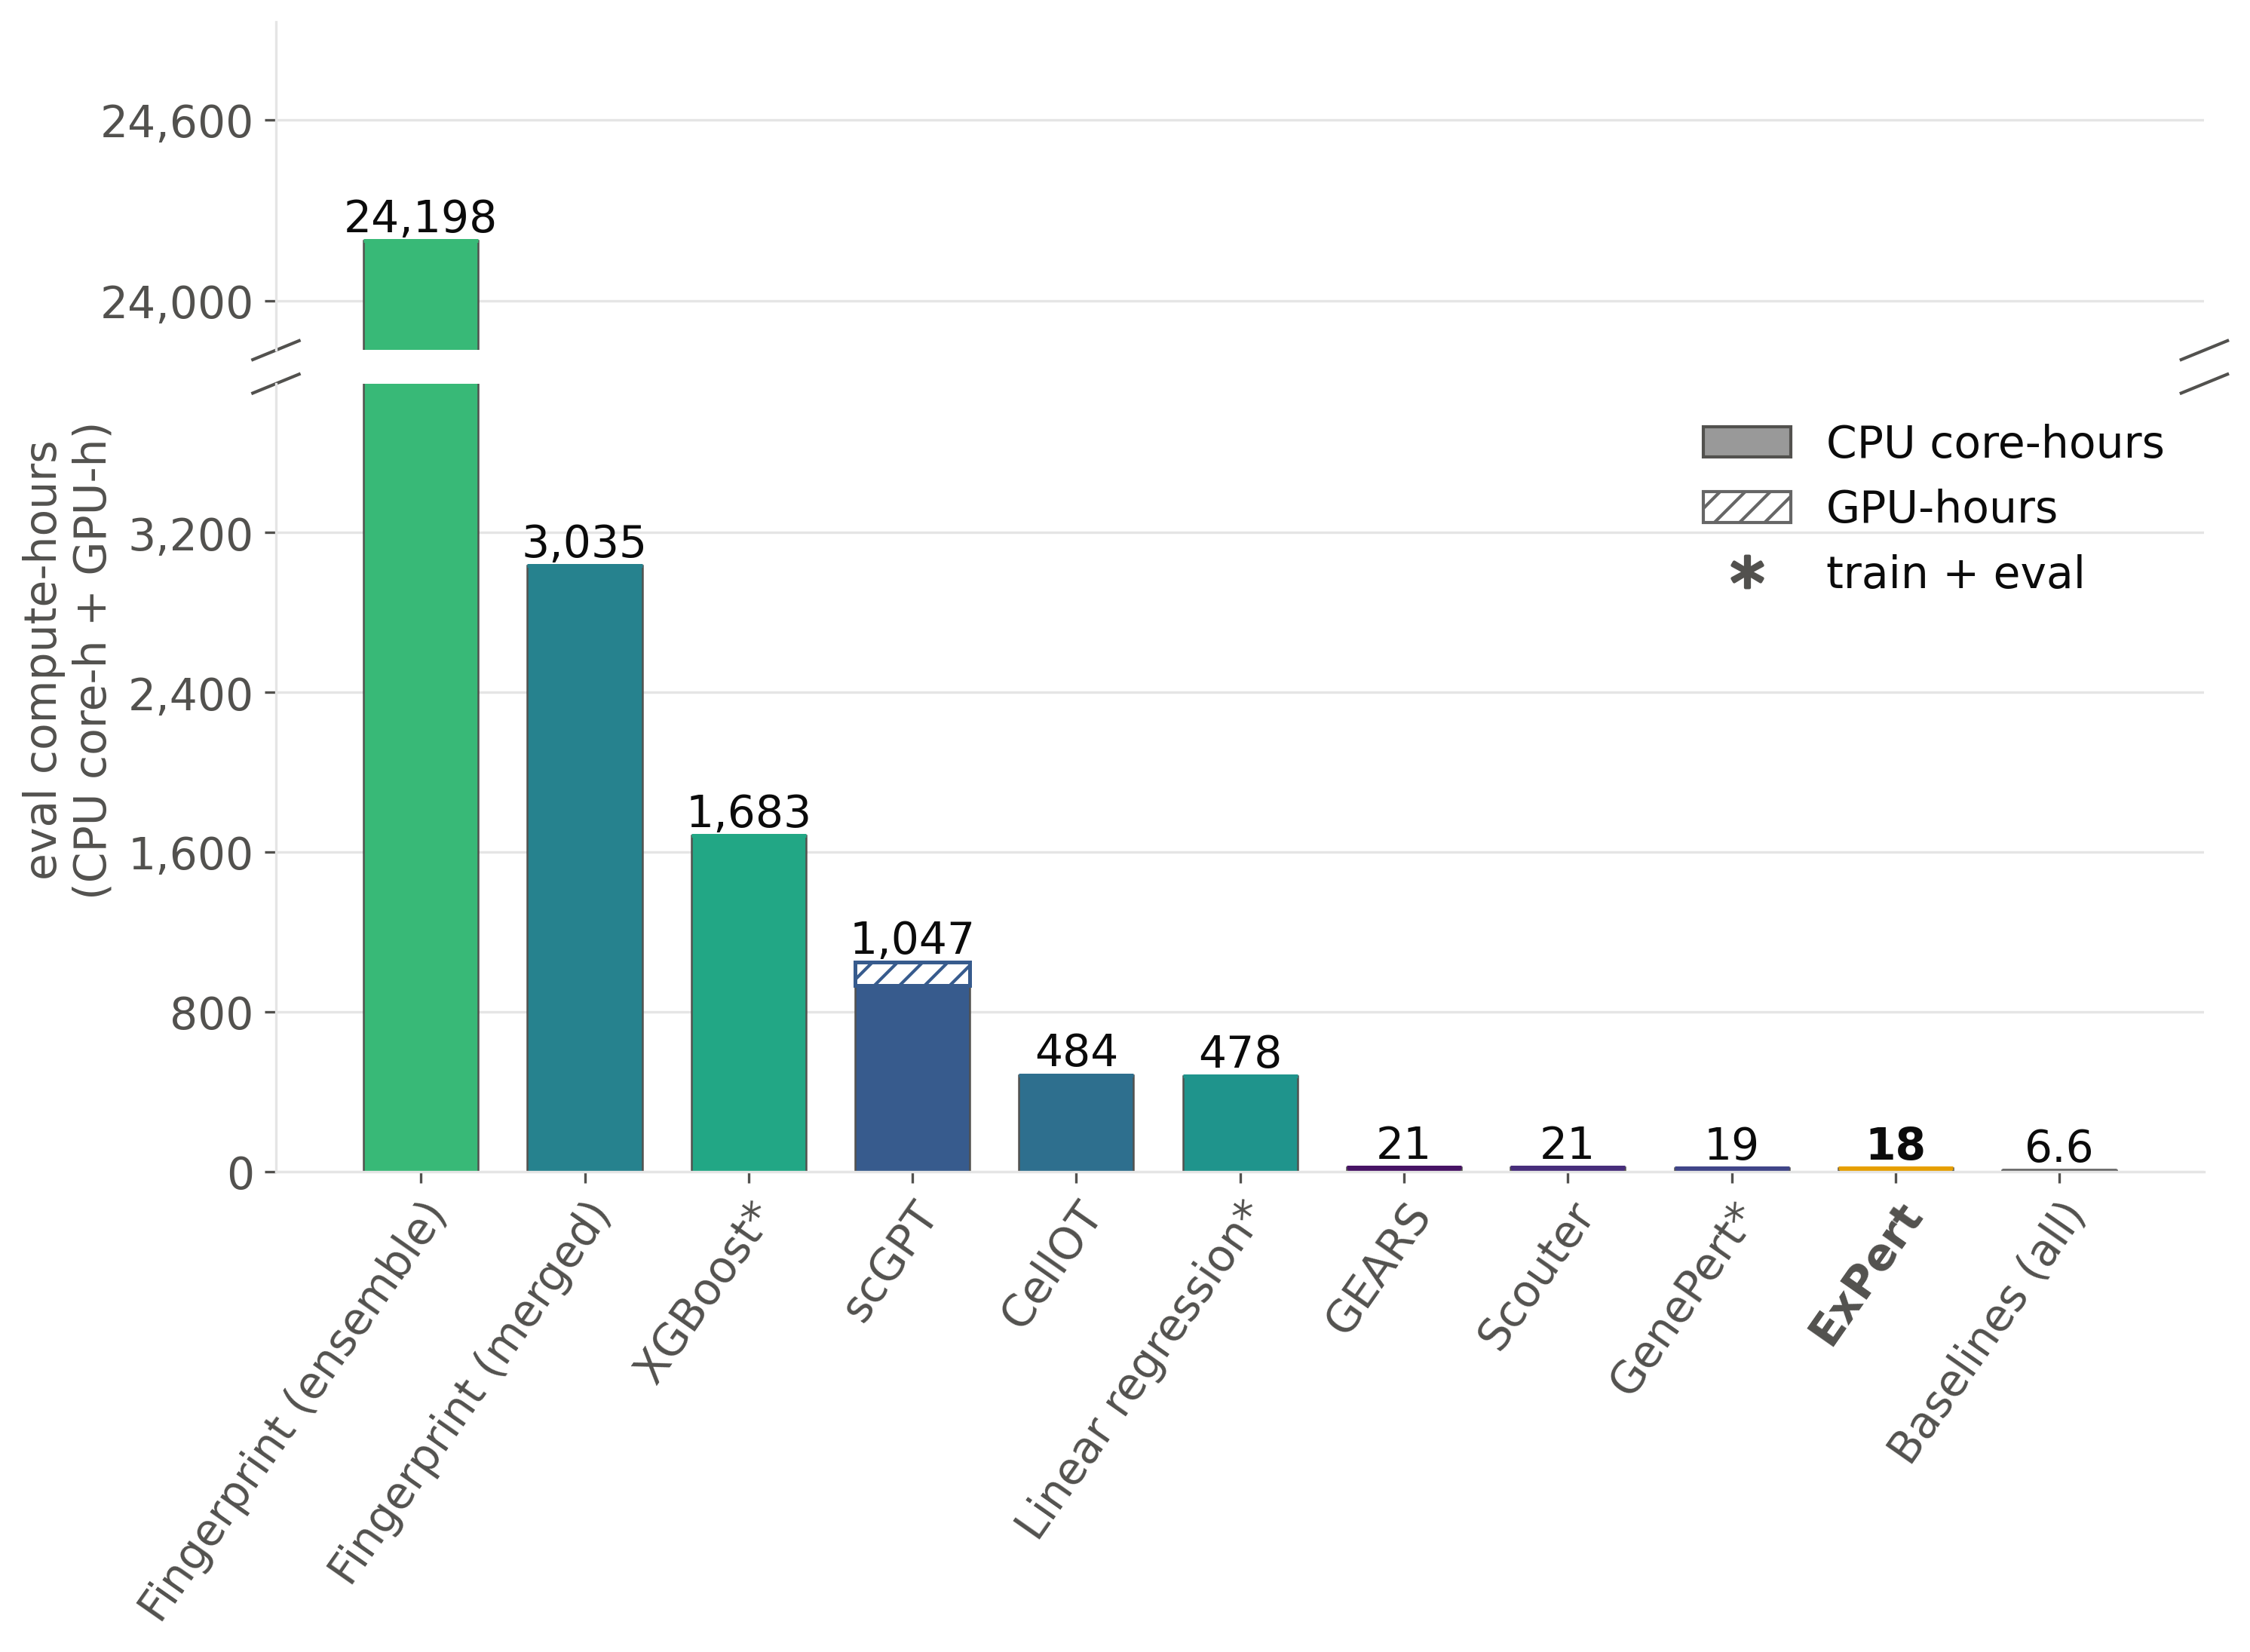

In [7]:
P.panel_f_compute(DATA, OUT)   # caption panel E is the file fig2f_eval_compute (file letters E/F are swapped vs the caption)
nb.show(OUT, 'fig2f_eval_compute')

## F — OOD top-10 recall vs total evaluation compute

Some labels are too long, can't fit inside the X axis


Some labels are too long, can't fit inside the X axis


Some labels are too long, can't fit inside the X axis


  wrote fig2e_cost.svg / .png


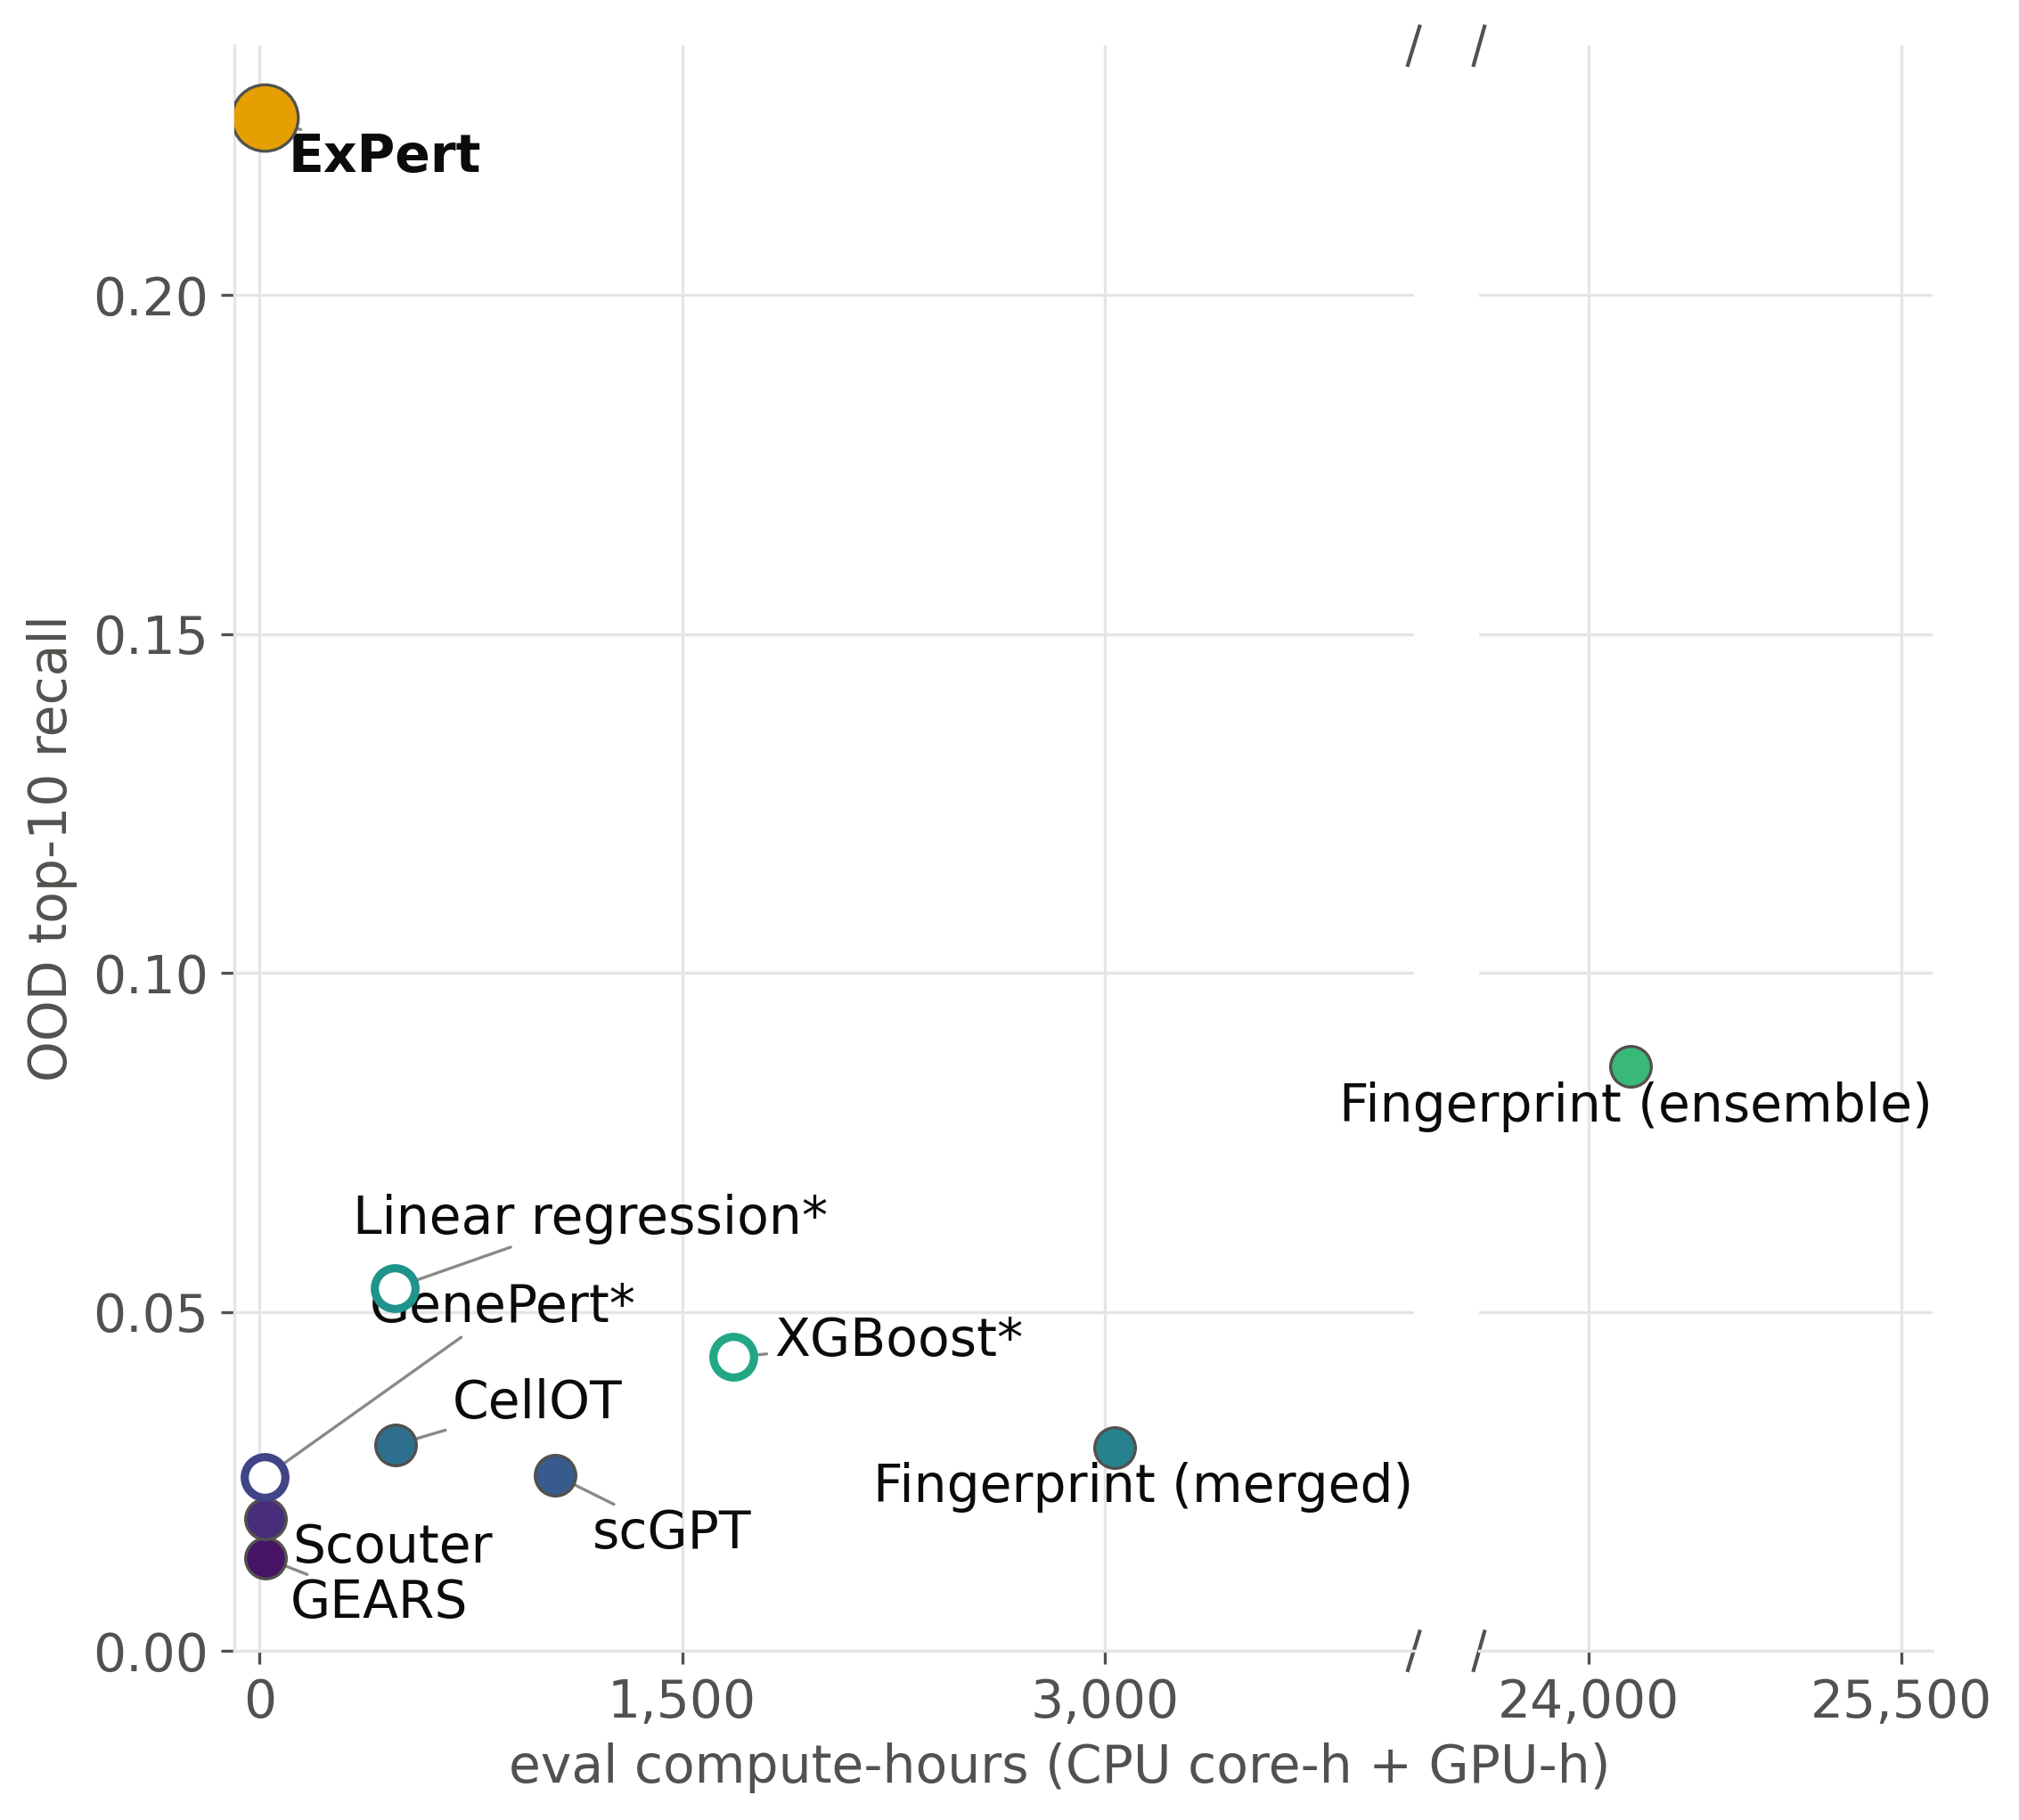

In [8]:
P.panel_e_cost(DATA, OUT, metrics)   # caption panel F is the file fig2e_cost; the reading-guide inset is added in the assembled figure, not drawn here
nb.show(OUT, 'fig2e_cost')

## G — evaluation compute-hours per fold, 200 → 1,157 perturbations

  wrote fig2g_scaling_compute.svg / .png


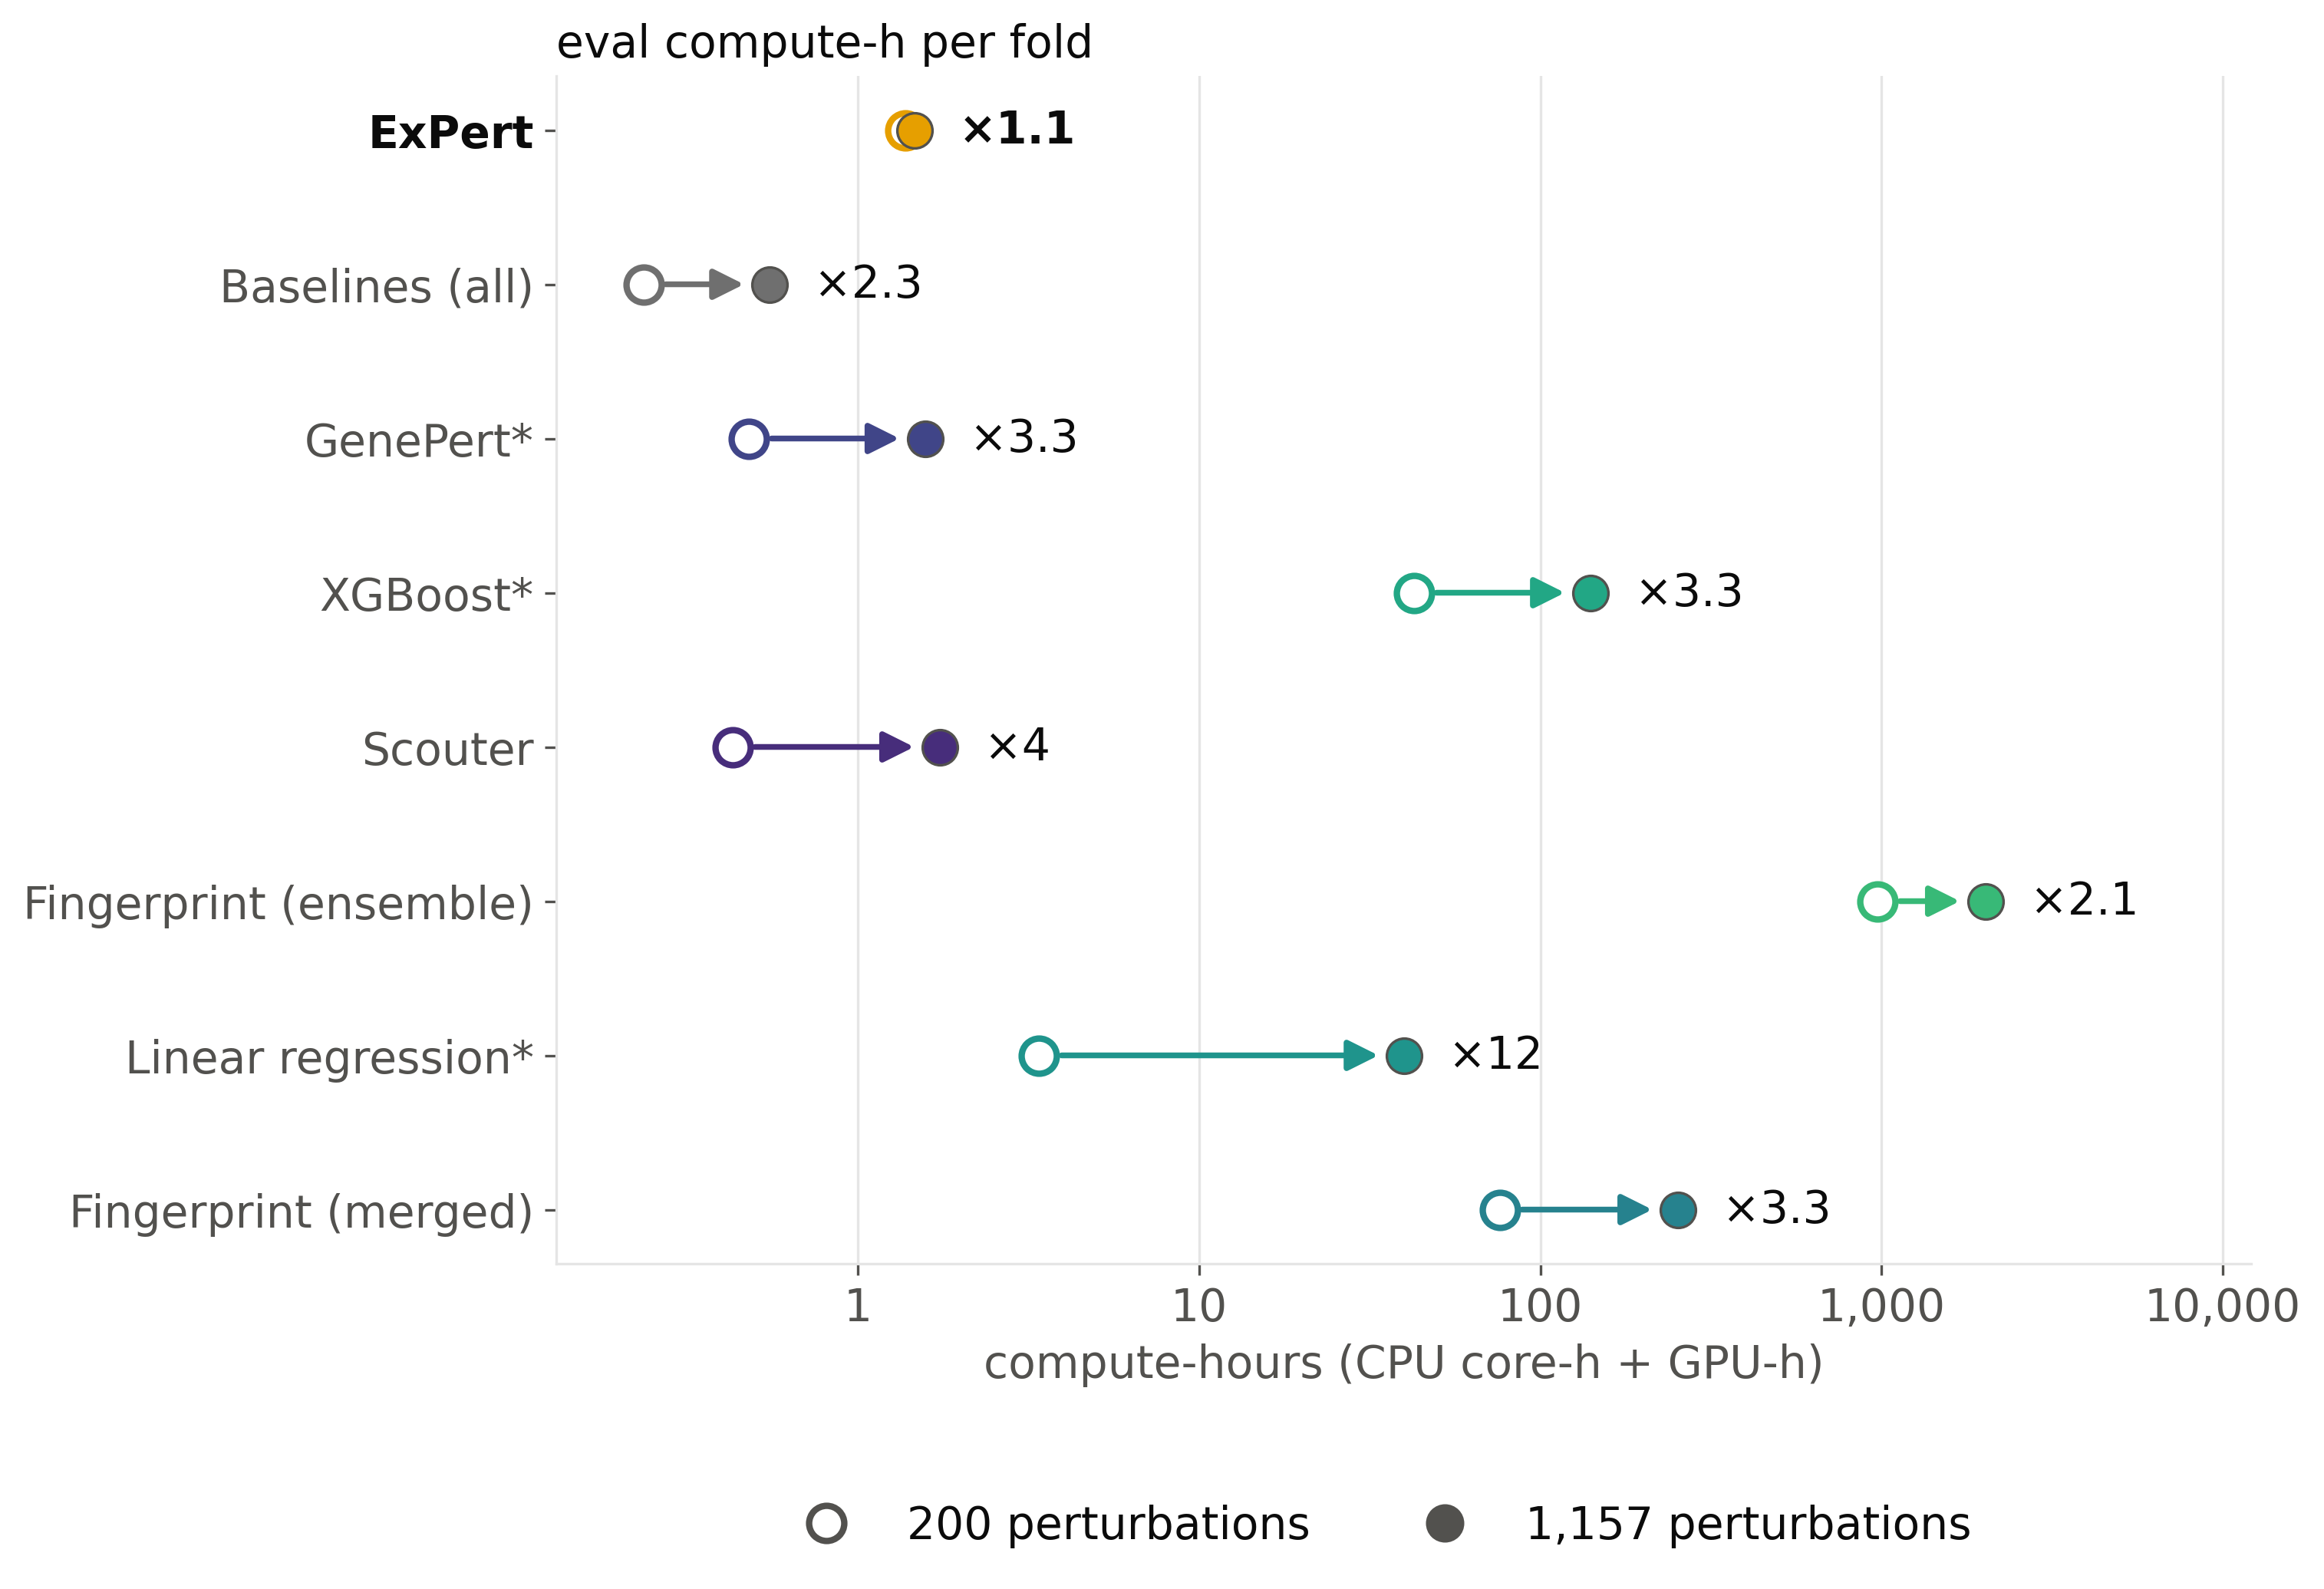

In [9]:
P.panel_g_compute(DATA, OUT)
nb.show(OUT, 'fig2g_scaling_compute')

## H — SLURM jobs per fold, 200 → 1,157 perturbations

  wrote fig2h_scaling_jobs.svg / .png


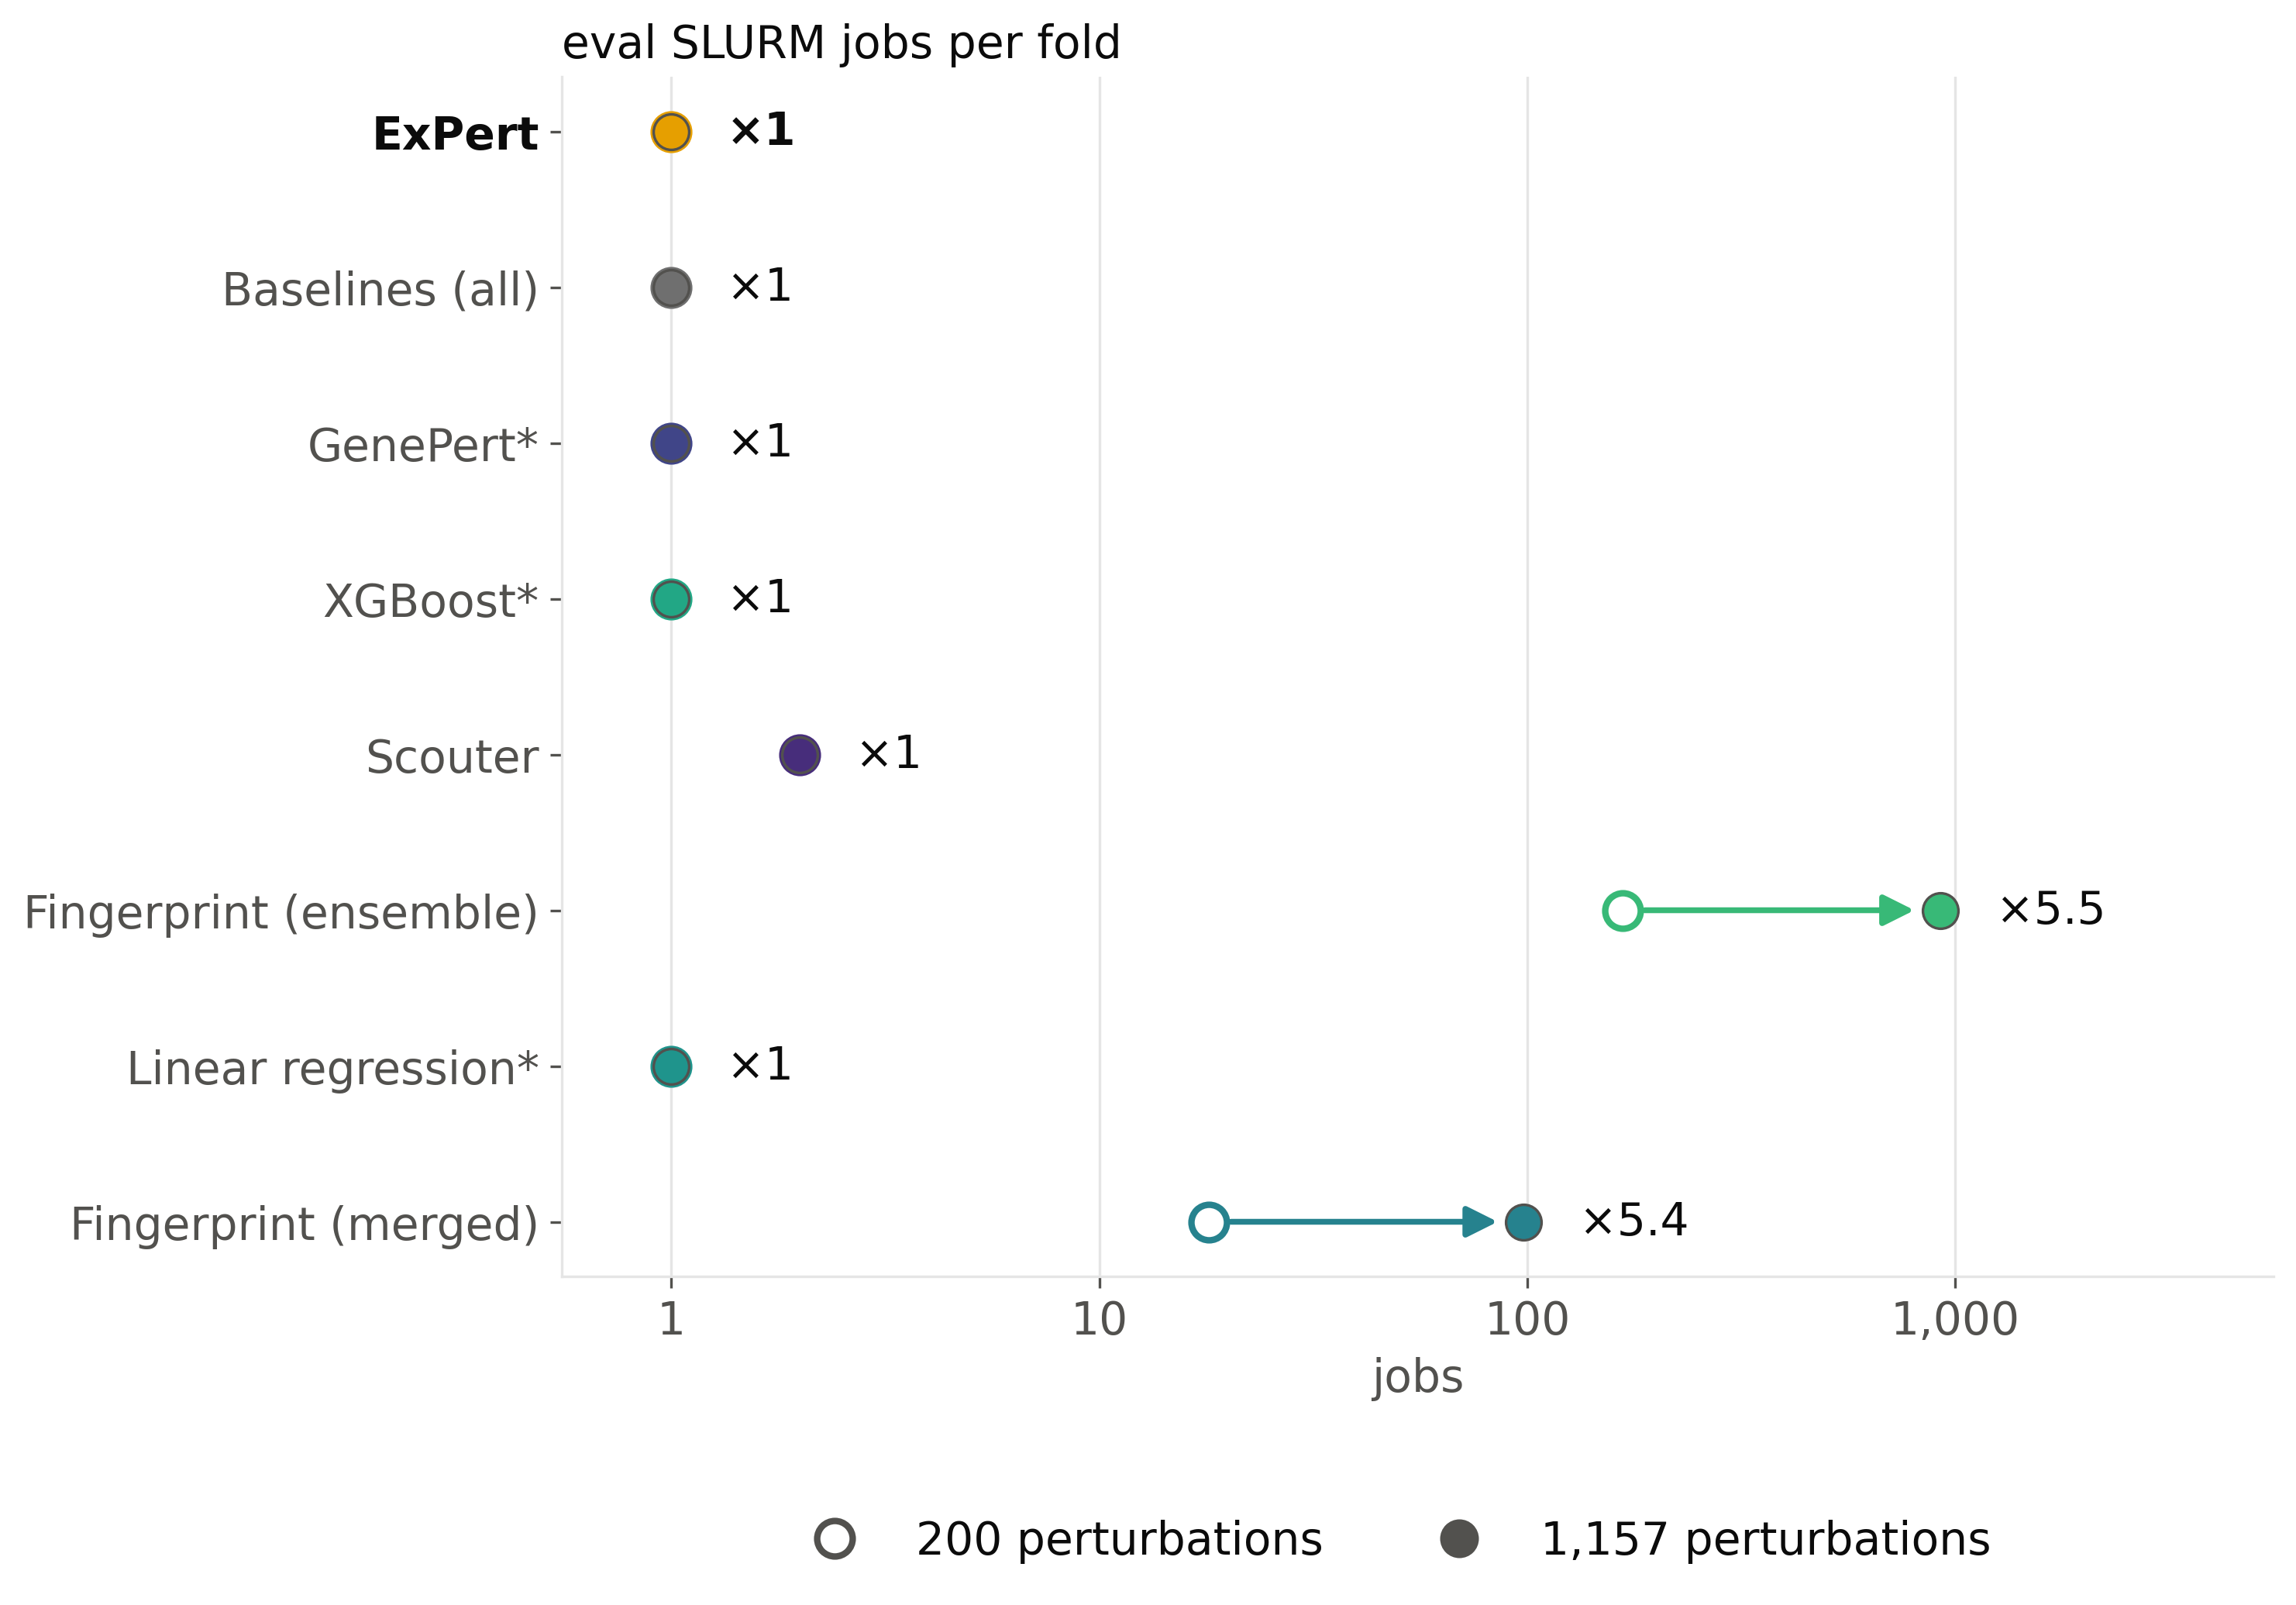

In [10]:
P.panel_h_jobs(DATA, OUT)
nb.show(OUT, 'fig2h_scaling_jobs')

## I — scaling exponent b of the combined cost (compute-h × jobs)

  wrote fig2i_scaling_exponents.svg / .png


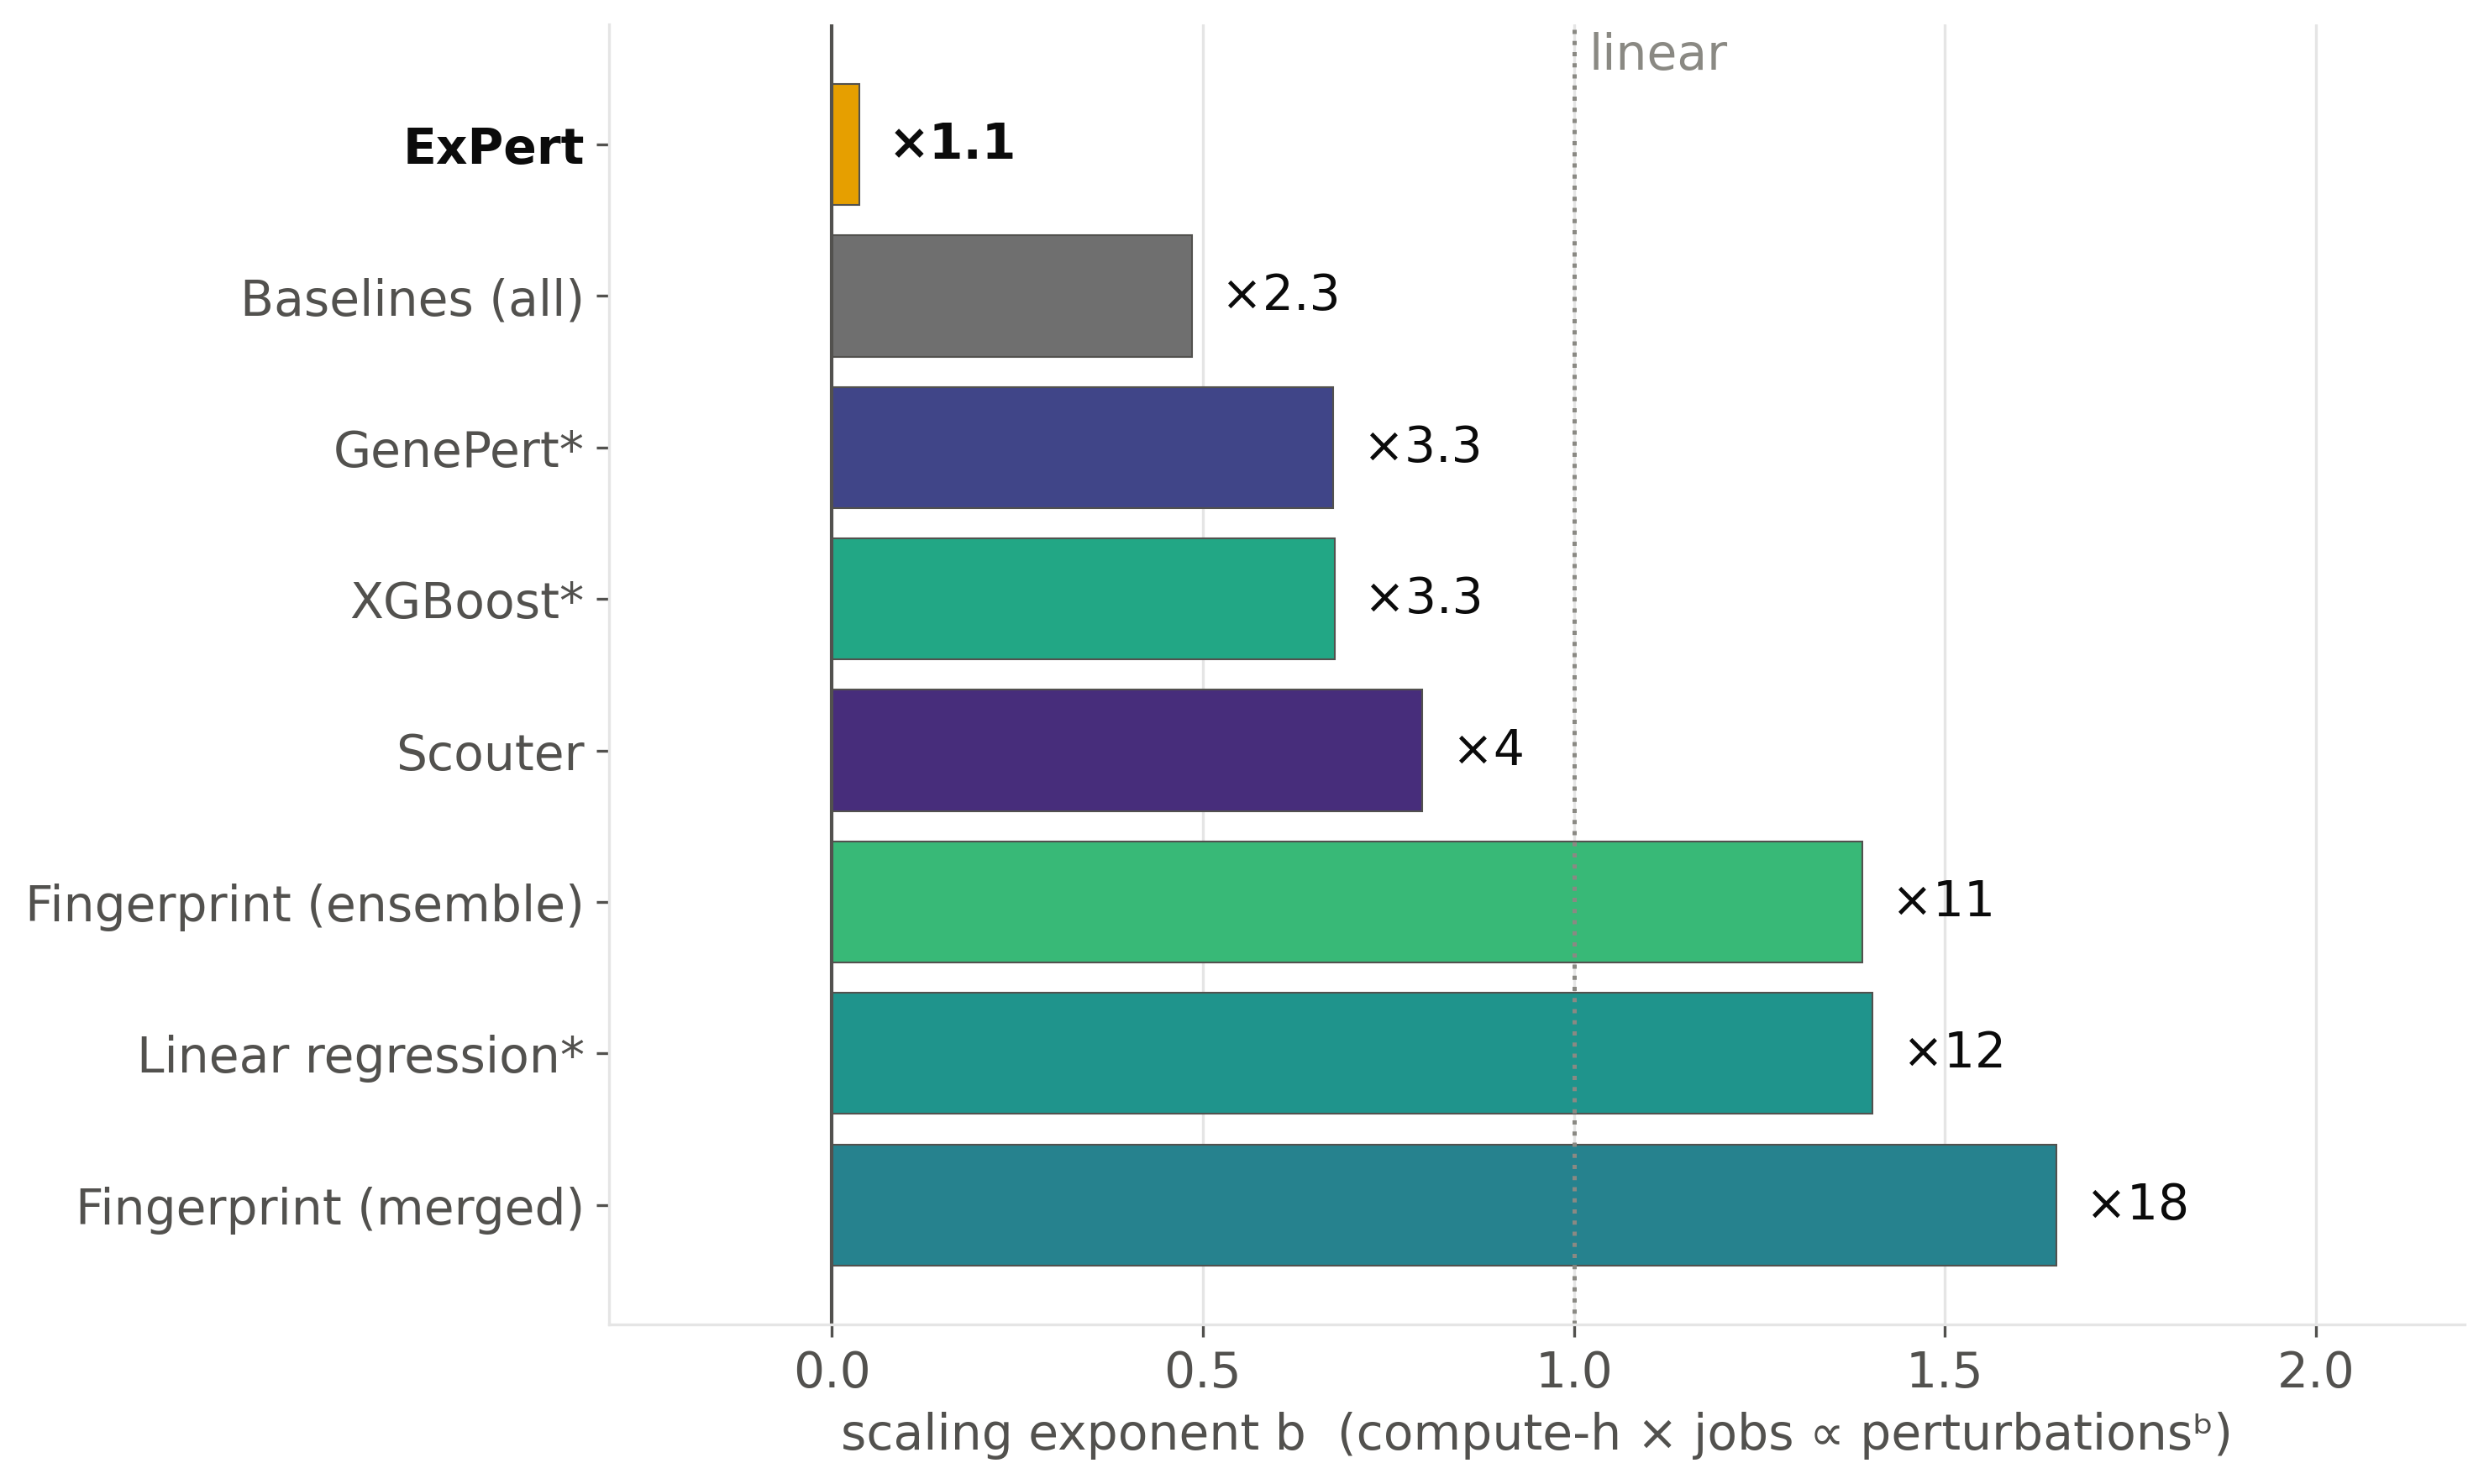

In [11]:
P.panel_i_exponents(DATA, OUT)
nb.show(OUT, 'fig2i_scaling_exponents')